# 01 · Data Cleaning
**Case study: AI Operations Audit — Top 3 Time Drains at a Mid-Sized Japanese 3PL**

The client is a third-party logistics provider in the Kanto region with ~60 office staff (Customer Service, Operations, Finance, Sales Admin, Management). They export 12 months of time-tracking data (Nov 2025 – Oct 2026) plus operational records from their ticketing system, WMS and ERP.

This notebook turns the raw exports into analysis-ready tables:

1. Load and profile the raw files
2. Clean `time_logs` (labels, dates, duplicates, durations)
3. Light checks on tickets, shipping documents and carrier invoices
4. Save processed files to `data/processed/`

> Data note: this is a case study built on realistic synthetic data. Company details are not used.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

RAW = Path("../data/raw")
PROC = Path("../data/processed")
PROC.mkdir(parents=True, exist_ok=True)

employees = pd.read_csv(RAW / "employees.csv")
logs = pd.read_csv(RAW / "time_logs.csv")
tickets = pd.read_csv(RAW / "cs_tickets.csv", parse_dates=["created_at"])
docs = pd.read_csv(RAW / "shipping_documents.csv", parse_dates=["received_date"])
invoices = pd.read_csv(RAW / "carrier_invoice_lines.csv")
survey = pd.read_csv(RAW / "employee_survey.csv")

for name, df in [("employees", employees), ("time_logs", logs), ("cs_tickets", tickets),
                 ("shipping_documents", docs), ("carrier_invoice_lines", invoices), ("employee_survey", survey)]:
    print(f"{name:24s} {df.shape[0]:>8,} rows x {df.shape[1]} cols")

employees                      60 rows x 6 cols
time_logs                 165,922 rows x 7 cols
cs_tickets                 26,000 rows x 9 cols
shipping_documents         41,000 rows x 10 cols
carrier_invoice_lines      34,000 rows x 10 cols
employee_survey                56 rows x 8 cols


## 1. Profile the time logs
The time-tracking export is the backbone of the audit, so it gets the most attention.

In [2]:
logs.head()

,log_id,employee_id,work_date,task_type,system,items_handled,duration_min
0,L0000001,E001,2025-11-04,Shipment status inquiry (WISMO),Email/Phone,5,52.4
1,L0000002,E001,2025-11-04,Shipment status inquiry (WISMO),Email/Phone,4,30.2
2,L0000003,E001,2025-11-04,Shipment status inquiry (WISMO),Email/Phone,6,55.5
3,L0000004,E001,2025-11-04,Delivery exception handling,TMS,2,34.4
4,L0000005,E001,2025-11-04,Delivery exception handling,TMS,1,26.0


In [3]:
print("Missing values:\n", logs.isna().sum(), "\n")
print("Distinct task labels:", logs["task_type"].nunique())
print("Exact duplicate rows:", logs.duplicated().sum())
print("Duration stats (min):\n", logs["duration_min"].describe().round(1))

Missing values:
 log_id             0
employee_id        0
work_date          0
task_type          0
system             0
items_handled      0
duration_min     996
dtype: int64 

Distinct task labels: 123
Exact duplicate rows: 1967
Duration stats (min):
 count    164926.0
mean         38.6
std          22.6
min         -66.9
25%          29.1
50%          36.6
75%          46.5
max        1360.7
Name: duration_min, dtype: float64


Four problems stand out:

- **Labels**: only ~25 real task types, but 100+ distinct spellings (case, extra spaces).
- **Duplicates**: entries submitted twice.
- **Durations**: missing values, negative values (sign error) and entries of 10–23 hours (timer left running).
- **Dates**: a mix of `YYYY-MM-DD` and the Japanese-style `YYYY/MM/DD`.

In [4]:
logs["task_type"].value_counts().tail(8)

task_type
Sales  reporting        30
TRAINING / ADMIN        28
MANAGEMENT REPORTING    26
Finance  reporting      26
CS REPORTING            23
SALES REPORTING         17
FINANCE REPORTING       16
MONTH-END CLOSE         15
Name: count, dtype: int64

## 2. Clean the time logs

In [5]:
before = len(logs)
tl = logs.copy()

# 2a. Normalise task labels -> canonical names
canon = (tl["task_type"].str.strip().str.replace(r"\s+", " ", regex=True))
lookup = (canon.groupby(canon.str.lower()).agg(lambda s: s.value_counts().idxmax()))  # most common spelling wins
tl["task_type"] = canon.str.lower().map(lookup)
print("Task labels after cleaning:", tl["task_type"].nunique())

# 2b. Parse mixed date formats
tl["work_date"] = pd.to_datetime(tl["work_date"].str.replace("/", "-"), format="%Y-%m-%d")

# 2c. Remove duplicate submissions (same log_id submitted twice)
dup = tl.duplicated(subset=["log_id"])
tl = tl[~dup]
print("Duplicates removed:", dup.sum())

Task labels after cleaning: 25
Duplicates removed: 1967


In [6]:
# 2d. Fix durations
neg = tl["duration_min"] < 0
tl.loc[neg, "duration_min"] = tl.loc[neg, "duration_min"].abs()          # sign error
runaway = tl["duration_min"] > 480                                       # a single block > 8h is not credible
tl["duration_flag"] = np.select([tl["duration_min"].isna(), runaway, neg],
                                ["imputed_missing", "imputed_runaway", "sign_fixed"], "ok")
tl.loc[runaway, "duration_min"] = np.nan
median_by_task = tl.groupby(["employee_id", "task_type"])["duration_min"].transform("median")
tl["duration_min"] = tl["duration_min"].fillna(median_by_task).round(1)

print(tl["duration_flag"].value_counts())
print("Remaining missing durations:", tl["duration_min"].isna().sum())

duration_flag
ok                 162824
imputed_missing       982
sign_fixed             89
imputed_runaway        60
Name: count, dtype: int64
Remaining missing durations: 0


In [7]:
# 2e. Enrich: division, hourly cost, cost of each entry, calendar fields
tl = tl.merge(employees[["employee_id", "division", "hourly_cost_jpy"]], on="employee_id", how="left")
tl["hours"] = tl["duration_min"] / 60
tl["cost_jpy"] = tl["hours"] * tl["hourly_cost_jpy"]
tl["month"] = tl["work_date"].dt.to_period("M").astype(str)
print(f"Rows: {before:,} -> {len(tl):,}")
tl.head()

Rows: 165,922 -> 163,955


,log_id,employee_id,work_date,task_type,system,items_handled,duration_min,duration_flag,division,hourly_cost_jpy,hours,cost_jpy,month
0,L0000001,E001,2025-11-04,Shipment status inquiry (WISMO),Email/Phone,5,52.4,ok,Customer Service,3060,0.873333,2672.4,2025-11
1,L0000002,E001,2025-11-04,Shipment status inquiry (WISMO),Email/Phone,4,30.2,ok,Customer Service,3060,0.503333,1540.2,2025-11
2,L0000003,E001,2025-11-04,Shipment status inquiry (WISMO),Email/Phone,6,55.5,ok,Customer Service,3060,0.925000,2830.5,2025-11
3,L0000004,E001,2025-11-04,Delivery exception handling,TMS,2,34.4,ok,Customer Service,3060,0.573333,1754.4,2025-11
4,L0000005,E001,2025-11-04,Delivery exception handling,TMS,1,26.0,ok,Customer Service,3060,0.433333,1326.0,2025-11


### Sanity check: hours logged per person per working day
After cleaning, a typical day should land around 7–8.5 hours (with overtime in busy months).

count    13564.00
mean         7.71
std          0.56
min          5.74
25%          7.32
50%          7.68
75%          8.06
max          9.86
Name: hours, dtype: float64


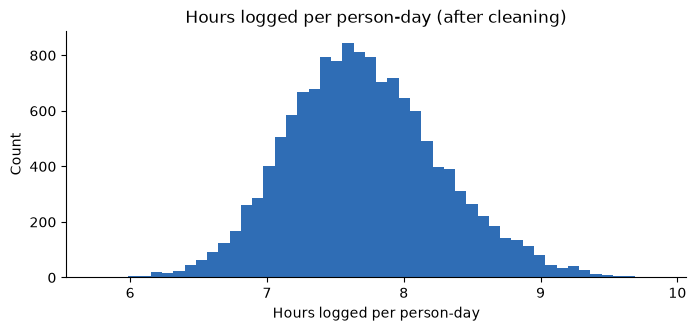

In [8]:
import matplotlib.pyplot as plt
per_day = tl.groupby(["employee_id", "work_date"])["hours"].sum()
print(per_day.describe().round(2))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(per_day, bins=50, color="#2f6db5")
ax.set_xlabel("Hours logged per person-day"); ax.set_ylabel("Count")
ax.set_title("Hours logged per person-day (after cleaning)")
ax.spines[["top", "right"]].set_visible(False)

## 3. Checks on the other sources

In [9]:
# CS tickets: some tickets were never tagged by agents
print("Tickets without category:", tickets["category"].isna().sum(),
      f"({tickets['category'].isna().mean():.1%})")
tickets["month"] = tickets["created_at"].dt.to_period("M").astype(str)
tickets["is_labeled"] = tickets["category"].notna()

# Shipping documents
docs["month"] = docs["received_date"].dt.to_period("M").astype(str)
docs["total_min"] = docs["entry_min"] + docs["rework_min"]
print("Docs with keying errors:", f"{(docs['field_errors'] > 0).mean():.1%}")

# Carrier invoices
invoices["overbilled_jpy"] = invoices["billed_amount_jpy"] - invoices["expected_amount_jpy"]
invoices["is_mismatch"] = invoices["overbilled_jpy"] > 0
print("Invoice lines with mismatch:", f"{invoices['is_mismatch'].mean():.1%}")
print("Survey response rate:", f"{len(survey) / len(employees):.0%}")

Tickets without category: 1046 (4.0%)
Docs with keying errors: 24.4%
Invoice lines with mismatch: 13.8%
Survey response rate: 93%


## 4. Save processed data

In [10]:
tl.to_csv(PROC / "time_logs_clean.csv", index=False)
tickets.to_csv(PROC / "cs_tickets_clean.csv", index=False)
docs.to_csv(PROC / "shipping_documents_clean.csv", index=False)
invoices.to_csv(PROC / "carrier_invoices_clean.csv", index=False)
employees.to_csv(PROC / "employees.csv", index=False)
survey.to_csv(PROC / "employee_survey.csv", index=False)
for f in sorted(PROC.glob("*.csv")):
    print(f"{f.name:32s} {f.stat().st_size / 1e6:6.1f} MB")

carrier_invoices_clean.csv          3.2 MB
cs_tickets_clean.csv                5.0 MB
employee_survey.csv                 0.0 MB
employees.csv                       0.0 MB
shipping_documents_clean.csv        3.3 MB
time_logs_clean.csv                19.7 MB
